In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy import random
from scipy.stats import uniform
from scipy.stats import norm
from scipy.stats import uniform
from scipy.stats import t


df = pd.read_csv(r"C:\Users\Adria\Desktop\Quant\polish-bank-risk-monitor\data\raw\pko.csv")
print(df.shape)
print(df.columns.tolist())
df.head(3)

(1523, 6)
['Data', 'Otwarcie', 'Najwyzszy', 'Najnizszy', 'Zamkniecie', 'Wolumen']


,Data,Otwarcie,Najwyzszy,Najnizszy,Zamkniecie,Wolumen
0,2020-10-01,16.3101,16.3254,15.9831,16.0364,1.856062e+06
1,2020-10-02,15.8159,16.3634,15.7703,16.2112,1.709034e+06
2,2020-10-05,16.3862,16.6751,16.3406,16.6675,2.482573e+06


In [2]:
def plot_pdf_cdf(dist,x_min,x_max,title) -> plt.Figure:
    
    x = np.linspace(x_min,x_max,500)
    
    fig,axes = plt.subplots(1,2, figsize = (11,5))
    axes[0].plot(x, dist.pdf(x))
    axes[0].set_title("PDF")
    axes[0].set_xlabel("x")

    axes[1].plot(x,dist.cdf(x))
    axes[1].set_title("CDF")
    axes[1].set_xlabel("x")
    fig.suptitle(title)
    fig.tight_layout()
    return fig    

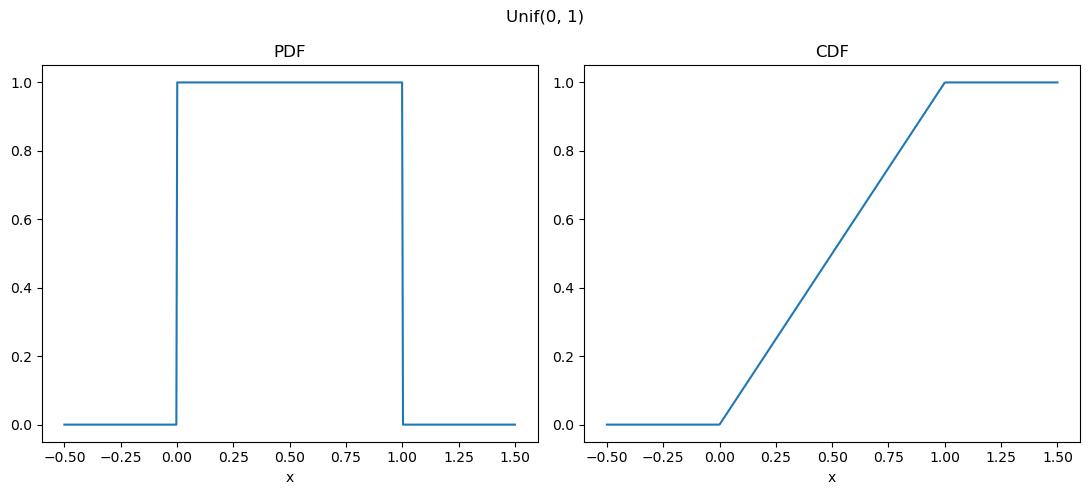

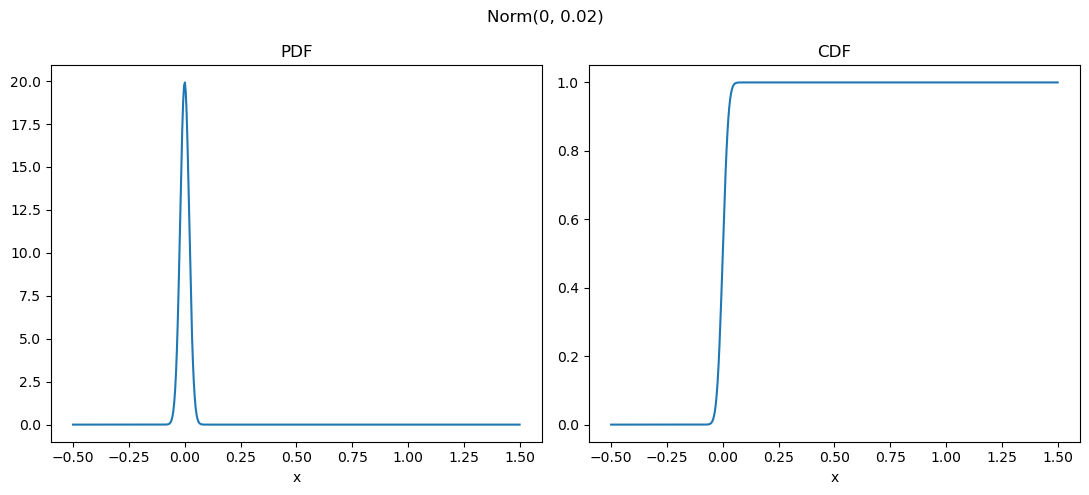

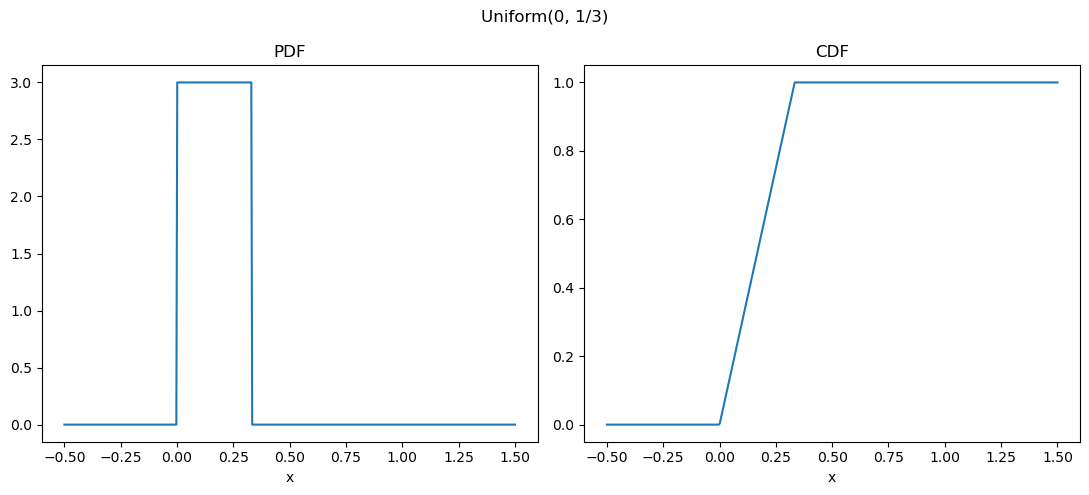

In [3]:
fig_unif = plot_pdf_cdf(uniform(0, 1), -0.5, 1.5, "Unif(0, 1)")
fig_norm = plot_pdf_cdf(norm(0, 0.02), -0.5, 1.5, "Norm(0, 0.02)")
fig_norm_2 = plot_pdf_cdf(uniform(0, 1/3), -0.5, 1.5, "Uniform(0, 1/3)")

In [4]:
returns = np.log(df["Zamkniecie"]).diff().dropna()
returns_mean = returns.mean()
returns_std = returns.std()

print(f"Mean daily return: {returns_mean:.4%}")
print(f"Std of daily returns: {returns_std:.4%}")

Mean daily return: 0.1292%
Std of daily returns: 2.1506%


<Axes: >

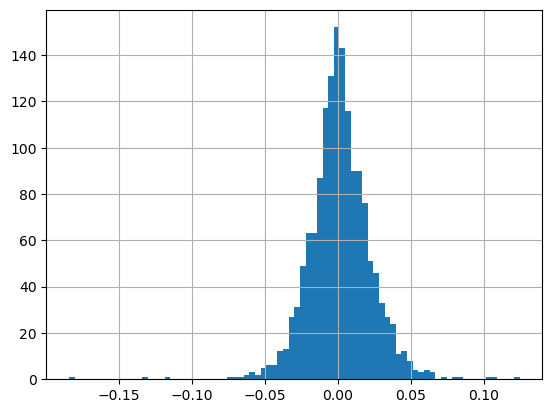

In [5]:
returns.hist(bins=80)

<Axes: >

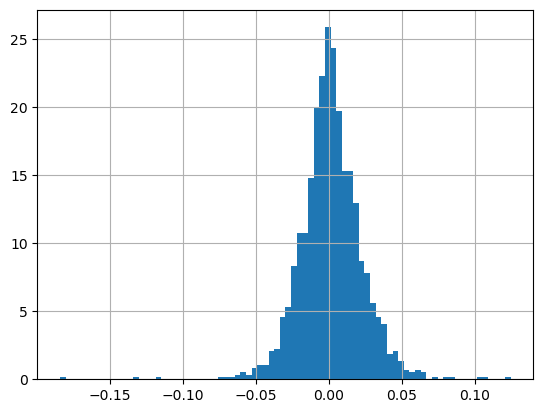

In [6]:
returns.hist(bins=80, density = True)


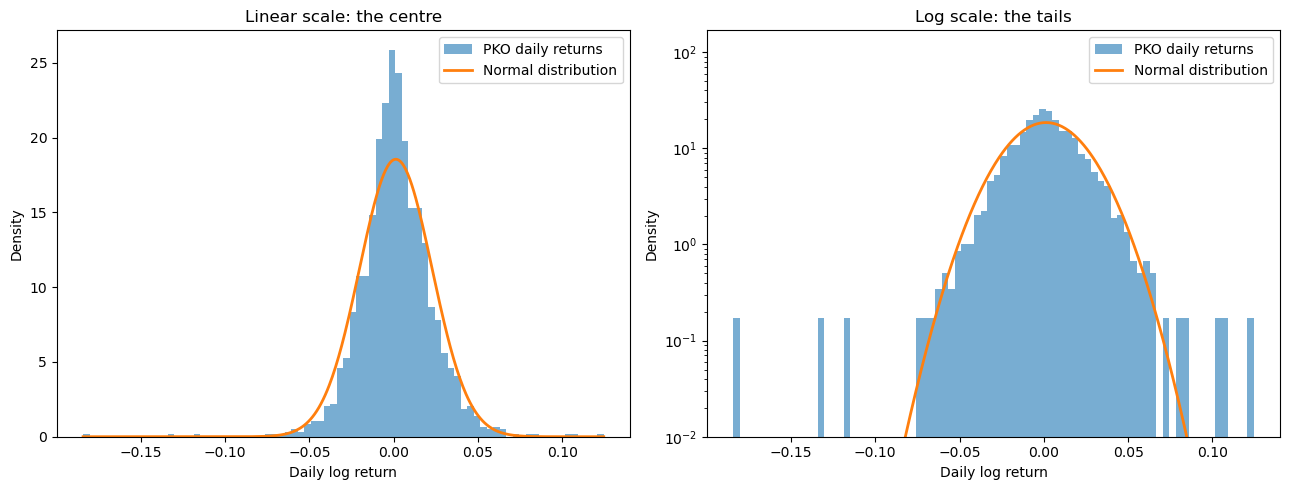

In [7]:
normal = norm(returns_mean, returns_std)
x = np.linspace(returns.min(), returns.max(), 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.hist(returns, bins=80, density=True, alpha=0.6, label="PKO daily returns")
    ax.plot(x, normal.pdf(x), linewidth=2, label="Normal distribution")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density")
    ax.legend()

axes[0].set_title("Linear scale: the centre")
axes[1].set_title("Log scale: the tails")
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1e-2)

fig.tight_layout()
plt.show()

In [8]:
returns_df = returns.sort_values()

In [9]:
returns_df = pd.DataFrame(returns.sort_values()).reset_index(drop=True).rename(columns = {"Zamkniecie":"sort"}).reset_index()
returns_df["index"] +=1
returns_df["empirical_distr"] = returns_df["index"]/len(returns_df)

In [10]:
print(returns_df["empirical_distr"].iloc[0], returns_df["empirical_distr"].iloc[-1])

0.000657030223390276 1.0


In [11]:
returns_df

,index,sort,empirical_distr
0,1,-0.184172,0.000657
1,2,-0.130432,0.001314
2,3,-0.116046,0.001971
3,4,-0.074546,0.002628
4,5,-0.069266,0.003285
...,...,...,...
1517,1518,0.081801,0.997372
1518,1519,0.084304,0.998029
1519,1520,0.102608,0.998686
1520,1521,0.106656,0.999343


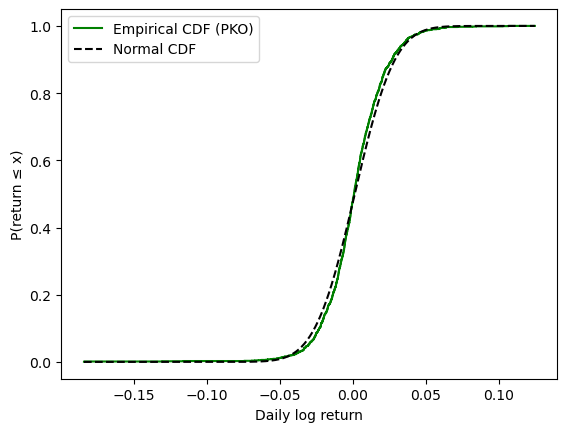

In [12]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()

In [13]:
## T student

t_df, t_loc, t_scale = t.fit(returns)
student = t(t_df, t_loc, t_scale)

print(f"Degrees of freedom: {t_df:.2f}")

Degrees of freedom: 4.95


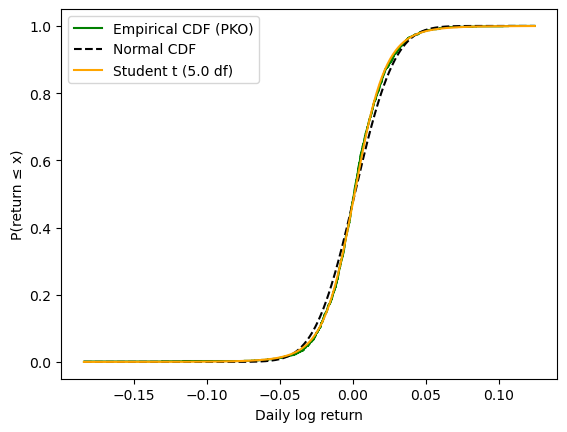

In [14]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.plot(x_grid, student.cdf(x_grid), color="orange", label=f"Student t ({t_df:.1f} df)")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()

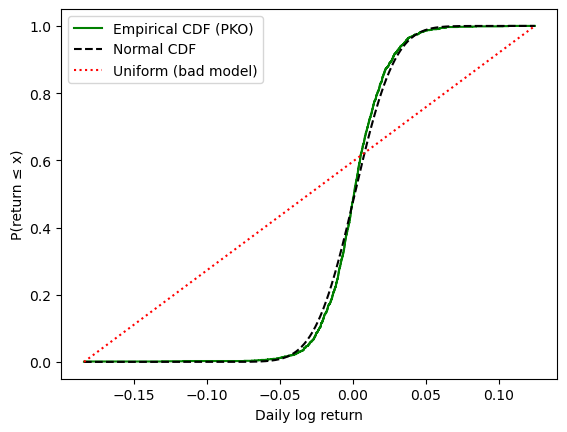

In [15]:
x = returns_df["sort"]
y = returns_df["empirical_distr"]
bad = uniform(loc=returns.min(), scale=returns.max() - returns.min())

fig, ax = plt.subplots()
ax.step(x, y, color="green", label="Empirical CDF (PKO)")
x_grid = np.linspace(x.min(), x.max(), 500)
ax.plot(x_grid, normal.cdf(x_grid), color="black", linestyle="--", label="Normal CDF")
ax.plot(x_grid, bad.cdf(x_grid), color="red", linestyle=":", label="Uniform (bad model)")
ax.set_xlabel("Daily log return")
ax.set_ylabel("P(return ≤ x)")
ax.legend()
plt.show()